# Assignment 02 — CNN Architectures, Training & Ablation Studies
**Deep Learning (MSAI/MSDS/PhD-DS), Air University** · TensorFlow/Keras on Colab T4

**Run order:** Runtime → Change runtime type → **T4 GPU**, then *Runtime → Restart and run all*.
Every number in the final report must come from `results.csv` produced by this notebook. Nothing is copied from papers.

Sections: 0 Setup · 1 Part I numerical checks · 2 Part II architectures (evidence) · 3 LR sanity check · 4 Architecture benchmark (96×96) · 5 Ablation A0–A4 (64×64, A4 transfer) · 6 Results table, winner, test once, confusion matrix

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 0. Setup (writes `src/models.py` and `src/utils.py` so the notebook is self-contained)

In [ ]:
import os; os.makedirs('src', exist_ok=True); open('src/__init__.py','w').close()

In [ ]:
%%writefile src/models.py
"""CNN Assignment 02 - model definitions (TensorFlow / Keras only).

AlexNet, VGG16, GoogLeNet (Inception-v1) and ResNet-18 are implemented by hand.
All use a 10-way float32 logits head (use SparseCategoricalCrossentropy(from_logits=True)).
Ablation models A0-A3 are small custom CNNs for 64x64 inputs.
"""
import tensorflow as tf
from tensorflow.keras import layers, Model, Input

L = layers
NUM_CLASSES = 10


def logits_head(x, n=NUM_CLASSES, name="logits"):
    # Final Dense is float32 so that mixed_float16 stays numerically stable.
    return L.Dense(n, dtype="float32", name=name)(x)


# ----------------------------------------------------------------------------
# Part II-1  AlexNet  (Krizhevsky et al., 2012) adapted to 96x96x3
# ----------------------------------------------------------------------------
def build_alexnet(input_shape=(96, 96, 3), use_lrn=False, name="AlexNet"):
    """5 conv stages (96,256,384,384,256), first 11x11/s4, second 5x5, rest 3x3.
    Overlapping 3x3/s2 max-pool after conv1, conv2, conv5. FC 4096-4096 + dropout.
    Deviations: single-tower (no 2-GPU grouped conv); LRN omitted unless use_lrn=True;
    conv1 uses 'same' padding so a 96x96 input keeps a usable 24x24 map."""
    def lrn(t):
        # original LRN: depth_radius=2 (n=5), k=2, alpha=1e-4, beta=0.75
        return L.Lambda(lambda z: tf.nn.local_response_normalization(
            tf.cast(z, tf.float32), depth_radius=2, bias=2.0, alpha=1e-4, beta=0.75))(t)

    inp = Input(input_shape, name="image")
    x = L.Conv2D(96, 11, strides=4, padding="same", activation="relu", name="conv1")(inp)
    if use_lrn: x = lrn(x)
    x = L.MaxPool2D(3, strides=2, name="pool1")(x)
    x = L.Conv2D(256, 5, padding="same", activation="relu", name="conv2")(x)
    if use_lrn: x = lrn(x)
    x = L.MaxPool2D(3, strides=2, name="pool2")(x)
    x = L.Conv2D(384, 3, padding="same", activation="relu", name="conv3")(x)
    x = L.Conv2D(384, 3, padding="same", activation="relu", name="conv4")(x)
    x = L.Conv2D(256, 3, padding="same", activation="relu", name="conv5")(x)
    x = L.MaxPool2D(3, strides=2, name="pool5")(x)
    x = L.Flatten(name="flatten")(x)
    x = L.Dense(4096, activation="relu", name="fc6")(x)
    x = L.Dropout(0.5, name="drop6")(x)
    x = L.Dense(4096, activation="relu", name="fc7")(x)
    x = L.Dropout(0.5, name="drop7")(x)
    return Model(inp, logits_head(x), name=name)


# ----------------------------------------------------------------------------
# Part II-2  VGG16  (Simonyan & Zisserman, 2014)
# ----------------------------------------------------------------------------
def build_vgg16(input_shape=(96, 96, 3), gap_head=False, name="VGG16"):
    cfg = [(2, 64), (2, 128), (3, 256), (3, 512), (3, 512)]
    inp = Input(input_shape, name="image")
    x = inp
    for b, (n, f) in enumerate(cfg, 1):
        for i in range(1, n + 1):
            x = L.Conv2D(f, 3, padding="same", activation="relu", name=f"block{b}_conv{i}")(x)
        x = L.MaxPool2D(2, strides=2, name=f"block{b}_pool")(x)
    if gap_head:
        x = L.GlobalAveragePooling2D(name="gap")(x)
    else:
        x = L.Flatten(name="flatten")(x)
        x = L.Dense(4096, activation="relu", name="fc1")(x)
        x = L.Dropout(0.5)(x)
        x = L.Dense(4096, activation="relu", name="fc2")(x)
        x = L.Dropout(0.5)(x)
    return Model(inp, logits_head(x), name=name)


# ----------------------------------------------------------------------------
# Part II-3  GoogLeNet / Inception-v1  (Szegedy et al., 2015)
# ----------------------------------------------------------------------------
def inception_module(x, f1, f3r, f3, f5r, f5, fp, name):
    b1 = L.Conv2D(f1, 1, padding="same", activation="relu", name=f"{name}_1x1")(x)
    b2 = L.Conv2D(f3r, 1, padding="same", activation="relu", name=f"{name}_3x3_reduce")(x)
    b2 = L.Conv2D(f3, 3, padding="same", activation="relu", name=f"{name}_3x3")(b2)
    b3 = L.Conv2D(f5r, 1, padding="same", activation="relu", name=f"{name}_5x5_reduce")(x)
    b3 = L.Conv2D(f5, 5, padding="same", activation="relu", name=f"{name}_5x5")(b3)
    b4 = L.MaxPool2D(3, strides=1, padding="same", name=f"{name}_pool")(x)
    b4 = L.Conv2D(fp, 1, padding="same", activation="relu", name=f"{name}_pool_proj")(b4)
    for b in (b1, b2, b3, b4):  # matching spatial shapes before concatenation
        assert b.shape[1:3] == x.shape[1:3], f"{name}: spatial mismatch"
    return L.Concatenate(name=f"{name}_concat")([b1, b2, b3, b4])


INCEPTION_CFG = {  # (1x1, 3x3red, 3x3, 5x5red, 5x5, poolproj) -> out channels
    "3a": (64, 96, 128, 16, 32, 32),     # 256
    "3b": (128, 128, 192, 32, 96, 64),   # 480
    "4a": (192, 96, 208, 16, 48, 64),    # 512
    "4b": (160, 112, 224, 24, 64, 64),   # 512
    "4c": (128, 128, 256, 24, 64, 64),   # 512
    "4d": (112, 144, 288, 32, 64, 64),   # 528
    "4e": (256, 160, 320, 32, 128, 128), # 832
    "5a": (256, 160, 320, 32, 128, 128), # 832
    "5b": (384, 192, 384, 48, 128, 128), # 1024
}


def build_googlenet(input_shape=(96, 96, 3), name="GoogLeNet"):
    """Stem + 9 Inception modules. Auxiliary classifiers and LRN are NOT used (declared)."""
    inp = Input(input_shape, name="image")
    x = L.Conv2D(64, 7, strides=2, padding="same", activation="relu", name="stem_conv7")(inp)
    x = L.MaxPool2D(3, strides=2, padding="same", name="stem_pool1")(x)
    x = L.Conv2D(64, 1, padding="same", activation="relu", name="stem_conv1x1")(x)
    x = L.Conv2D(192, 3, padding="same", activation="relu", name="stem_conv3")(x)
    x = L.MaxPool2D(3, strides=2, padding="same", name="stem_pool2")(x)
    for k in ("3a", "3b"):
        x = inception_module(x, *INCEPTION_CFG[k], name=f"inception_{k}")
    x = L.MaxPool2D(3, strides=2, padding="same", name="pool3")(x)
    for k in ("4a", "4b", "4c", "4d", "4e"):
        x = inception_module(x, *INCEPTION_CFG[k], name=f"inception_{k}")
    x = L.MaxPool2D(3, strides=2, padding="same", name="pool4")(x)
    for k in ("5a", "5b"):
        x = inception_module(x, *INCEPTION_CFG[k], name=f"inception_{k}")
    x = L.GlobalAveragePooling2D(name="gap")(x)
    x = L.Dropout(0.4, name="drop")(x)
    return Model(inp, logits_head(x), name=name)


# ----------------------------------------------------------------------------
# Part II-4  ResNet-18  (He et al., 2016)
# ----------------------------------------------------------------------------
def basic_block(x, filters, stride, name):
    """Two 3x3 convs; identity shortcut, or 1x1 projection when shape changes."""
    in_ch = x.shape[-1]
    y = L.Conv2D(filters, 3, strides=stride, padding="same", use_bias=False, name=f"{name}_conv1")(x)
    y = L.BatchNormalization(name=f"{name}_bn1")(y)
    y = L.ReLU(name=f"{name}_relu1")(y)
    y = L.Conv2D(filters, 3, padding="same", use_bias=False, name=f"{name}_conv2")(y)
    y = L.BatchNormalization(name=f"{name}_bn2")(y)
    if stride != 1 or in_ch != filters:
        s = L.Conv2D(filters, 1, strides=stride, use_bias=False, name=f"{name}_proj")(x)
        s = L.BatchNormalization(name=f"{name}_proj_bn")(s)
    else:
        s = x
    assert s.shape[1:] == y.shape[1:], f"{name}: Add shape mismatch {s.shape} vs {y.shape}"
    out = L.Add(name=f"{name}_add")([y, s])
    return L.ReLU(name=f"{name}_out")(out)


def build_resnet18(input_shape=(96, 96, 3), name="ResNet18"):
    inp = Input(input_shape, name="image")
    x = L.Conv2D(64, 7, strides=2, padding="same", use_bias=False, name="stem_conv")(inp)
    x = L.BatchNormalization(name="stem_bn")(x)
    x = L.ReLU(name="stem_relu")(x)
    x = L.MaxPool2D(3, strides=2, padding="same", name="stem_pool")(x)
    for s, f in enumerate((64, 128, 256, 512), 1):
        for b in range(2):
            stride = 2 if (b == 0 and s > 1) else 1
            x = basic_block(x, f, stride, name=f"stage{s}_block{b+1}")
    x = L.GlobalAveragePooling2D(name="gap")(x)
    return Model(inp, logits_head(x), name=name)


# ----------------------------------------------------------------------------
# Part III  controlled ablation models (64x64x3)
# ----------------------------------------------------------------------------
def augmentation_block(name="augment"):
    """Label-preserving; active only when training=True."""
    return tf.keras.Sequential([
        L.RandomFlip("horizontal"),
        L.RandomTranslation(0.1, 0.1),
        L.RandomContrast(0.1),
    ], name=name)


def build_ablation(variant, input_shape=(64, 64, 3), seed=42):
    """variant in {A0, A1, A2, A3P, A3R}.
    A0 : [Conv-ReLU-Pool] x2 (32, 64) + GAP + Dense(10)
    A1 : A0 + BN after conv, before ReLU
    A2 : A1 + augmentation
    A3P: A2 + plain 'two-conv' blocks (stem 32; blocks 32, 64, 128)
    A3R: identical to A3P, + shortcut around each block's two convs
         (identity if channels match, else 1x1 projection conv)."""
    tf.keras.utils.set_random_seed(seed)
    use_bn = variant != "A0"
    use_aug = variant in ("A2", "A3P", "A3R")
    inp = Input(input_shape, name="image")
    x = augmentation_block()(inp) if use_aug else inp

    def conv(t, f, nm, relu=True):
        t = L.Conv2D(f, 3, padding="same", use_bias=not use_bn, name=nm)(t)
        if use_bn: t = L.BatchNormalization(name=nm + "_bn")(t)
        return L.ReLU(name=nm + "_relu")(t) if relu else t

    if variant in ("A0", "A1", "A2"):
        for i, f in enumerate((32, 64), 1):
            x = conv(x, f, f"blk{i}_conv")
            x = L.MaxPool2D(2, name=f"blk{i}_pool")(x)
    else:
        x = conv(x, 32, "stem")
        for i, f in enumerate((32, 64, 128), 1):
            h = conv(x, f, f"blk{i}_convA")
            h = conv(h, f, f"blk{i}_convB", relu=(variant == "A3P"))
            if variant == "A3R":
                if x.shape[-1] != f:
                    s = L.Conv2D(f, 1, use_bias=False, name=f"blk{i}_proj")(x)
                    s = L.BatchNormalization(name=f"blk{i}_proj_bn")(s)
                else:
                    s = x
                assert s.shape[1:] == h.shape[1:]
                h = L.ReLU(name=f"blk{i}_out")(L.Add(name=f"blk{i}_add")([h, s]))
            x = L.MaxPool2D(2, name=f"blk{i}_pool")(h)
    x = L.GlobalAveragePooling2D(name="gap")(x)
    return Model(inp, logits_head(x), name=variant)


# ----------------------------------------------------------------------------
# Part III  A4 transfer learning (ResNet50, ImageNet) - allowed only here
# ----------------------------------------------------------------------------
def build_transfer(input_shape=(128, 128, 3), dropout=0.2, weights="imagenet"):
    """Input must already be resnet50.preprocess_input()-ed (done in tf.data on 0-255 pixels)."""
    base = tf.keras.applications.ResNet50(include_top=False, weights=weights,
                                          input_shape=input_shape, name="resnet50_base")
    base.trainable = False
    inp = Input(input_shape, name="image")
    x = base(inp, training=False)            # BN stays in inference mode
    x = L.GlobalAveragePooling2D(name="gap")(x)
    x = L.Dropout(dropout, name="drop")(x)
    model = Model(inp, logits_head(x), name="A4")
    return model, base


def unfreeze_top(base, from_layer="conv5_block1_1_conv"):
    """Unfreeze conv5 stage; BatchNorm layers stay frozen. Caller MUST recompile."""
    base.trainable = True
    found = False
    for l in base.layers:
        if l.name == from_layer: found = True
        l.trainable = found and not isinstance(l, L.BatchNormalization)
    return sum(l.trainable for l in base.layers)


MODEL_BUILDERS = {"AlexNet": build_alexnet, "VGG16": build_vgg16,
                  "GoogLeNet": build_googlenet, "ResNet18": build_resnet18}


Writing src/models.py


In [ ]:
%%writefile src/utils.py
"""Data protocol, training harness, metrics and logging for CNN Assignment 02."""
import os, gc, json, time, subprocess, platform, csv
import numpy as np
import tensorflow as tf

SEED = 42
CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]
RESULTS_CSV = "results.csv"
LOG_DIR = "logs"
os.makedirs(LOG_DIR, exist_ok=True)


# ------------------------------------------------------------------ environment
def set_seed(seed):
    tf.keras.utils.set_random_seed(seed)


def setup_precision():
    gpus = tf.config.list_physical_devices("GPU")
    for g in gpus:
        try: tf.config.experimental.set_memory_growth(g, True)
        except Exception: pass
    if gpus:
        tf.keras.mixed_precision.set_global_policy("mixed_float16")
    return bool(gpus), tf.keras.mixed_precision.global_policy().name


def log_environment(path="environment.txt"):
    lines = [f"python {platform.python_version()}", f"tensorflow {tf.__version__}",
             f"keras {tf.keras.__version__}", f"seed {SEED}",
             f"policy {tf.keras.mixed_precision.global_policy().name}"]
    try:
        lines.append(subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
    except Exception:
        lines.append("nvidia-smi unavailable")
    try:
        c = subprocess.run(["git", "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()
        lines.append(f"git commit {c or 'n/a (not a git repo yet)'}")
    except Exception:
        lines.append("git commit n/a")
    open(path, "w").write("\n".join(lines))
    print("\n".join(lines))


# ------------------------------------------------------------------ data protocol
def load_cifar10_arrays():
    (xtr, ytr), (xte, yte) = tf.keras.datasets.cifar10.load_data()
    return xtr, ytr.ravel().astype("int64"), xte, yte.ravel().astype("int64")


def make_split(ytr, n_train=12000, n_val=3000, seed=SEED, path="data_indices.npz"):
    """Fixed, stratified, disjoint train/val subsets drawn ONLY from the 50k train partition."""
    from sklearn.model_selection import train_test_split
    idx = np.arange(len(ytr))
    tr_idx, rest = train_test_split(idx, train_size=n_train, stratify=ytr, random_state=seed)
    val_idx, _ = train_test_split(rest, train_size=n_val, stratify=ytr[rest], random_state=seed)
    assert len(set(tr_idx) & set(val_idx)) == 0
    np.savez(path, train_idx=tr_idx, val_idx=val_idx)
    return tr_idx, val_idx


def make_ds(x, y, size, batch, training, preprocess="scale", seed=SEED):
    """Resize on demand inside tf.data (no enlarged copies stored).
    preprocess: 'scale' -> /255 ; 'resnet50' -> keras resnet50.preprocess_input on 0-255 pixels."""
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if training:
        ds = ds.shuffle(len(x), seed=seed, reshuffle_each_iteration=True)

    def _map(img, lab):
        img = tf.image.resize(tf.cast(img, tf.float32), (size, size), method="bilinear")  # 0-255 scale
        if preprocess == "scale":
            img = img / 255.0
        else:
            img = tf.keras.applications.resnet50.preprocess_input(img)
        return img, lab

    return ds.map(_map, num_parallel_calls=tf.data.AUTOTUNE).batch(batch).prefetch(tf.data.AUTOTUNE)


# ------------------------------------------------------------------ harness
class TimeHistory(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None): self.t0 = time.time()
    def on_train_end(self, logs=None): self.total = time.time() - self.t0


def count_params(model):
    tr = int(sum(np.prod(w.shape) for w in model.trainable_weights))
    tot = int(model.count_params())
    return tr, tot


def macro_f1_and_preds(model, ds, y_true):
    from sklearn.metrics import f1_score
    probs = model.predict(ds, verbose=0)
    pred = np.argmax(probs, axis=1)
    return f1_score(y_true, pred, average="macro"), pred


def peak_gpu_mb():
    try:
        return tf.config.experimental.get_memory_info("GPU:0")["peak"] / 2**20
    except Exception:
        return float("nan")


def reset_gpu_peak():
    try: tf.config.experimental.reset_memory_stats("GPU:0")
    except Exception: pass


def append_row(row, path=RESULTS_CSV):
    new = not os.path.exists(path)
    with open(path, "a", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(row.keys()))
        if new: w.writeheader()
        w.writerow(row)


def run_experiment(run_id, make_model, make_train, make_val, y_val, *, arch, input_size,
                   seed, epochs, lr, batch_sizes=(32, 16), note="", compile_fn=None):
    """make_model() -> keras Model; make_train(bs)/make_val(bs) -> tf.data.
    Tries each batch size in turn on OOM (all attempts are logged). Checkpoint rule (identical
    for every run): keep weights of the epoch with highest val_accuracy.
    Returns (row, history_dict). Failed runs are logged, never dropped."""
    attempts = []
    for bs in batch_sizes:
        tf.keras.backend.clear_session(); gc.collect(); set_seed(seed); reset_gpu_peak()
        ckpt = os.path.join(LOG_DIR, f"{run_id}.weights.h5")
        try:
            model = make_model()
            if compile_fn is None:
                model.compile(tf.keras.optimizers.Adam(lr),
                              tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                              metrics=["accuracy"])
            else:
                compile_fn(model)
            th = TimeHistory()
            cb = [th, tf.keras.callbacks.ModelCheckpoint(ckpt, monitor="val_accuracy", mode="max",
                  save_best_only=True, save_weights_only=True)]
            hist = model.fit(make_train(bs), validation_data=make_val(bs), epochs=epochs,
                             callbacks=cb, verbose=2).history
            model.load_weights(ckpt)
            f1, _ = macro_f1_and_preds(model, make_val(bs), y_val)
            b = int(np.argmax(hist["val_accuracy"]))
            tr_p, tot_p = count_params(model)
            row = dict(run_id=run_id, architecture=arch, input_size=input_size, seed=seed,
                       trainable_params=tr_p, total_params=tot_p, epochs=len(hist["loss"]),
                       batch_size=bs, lr=lr, best_epoch=b + 1,
                       best_val_acc=round(hist["val_accuracy"][b], 4), macro_f1=round(f1, 4),
                       train_acc_at_best=round(hist["accuracy"][b], 4),
                       final_train_acc=round(hist["accuracy"][-1], 4),
                       gen_gap=round(hist["accuracy"][b] - hist["val_accuracy"][b], 4),
                       train_minutes=round(th.total / 60, 2), peak_gpu_mb=round(peak_gpu_mb(), 1),
                       status="ok", failed_batch_sizes=";".join(map(str, attempts)), note=note)
            append_row(row)
            json.dump(hist, open(os.path.join(LOG_DIR, f"{run_id}_history.json"), "w"))
            return row, hist
        except tf.errors.ResourceExhaustedError as e:
            attempts.append(bs)
            open(os.path.join(LOG_DIR, f"{run_id}_OOM.log"), "a").write(f"batch {bs}: {str(e)[:500]}\n")
            print(f"[{run_id}] OOM at batch {bs}; retrying smaller")
    row = dict(run_id=run_id, architecture=arch, input_size=input_size, seed=seed, status="OOM",
               failed_batch_sizes=";".join(map(str, attempts)), note=note)
    append_row(row)
    return row, None


def lr_sanity_check(make_model, x, y, size, lrs=(1e-4, 3e-4, 1e-3), n_fit=2000, n_eval=1000,
                    epochs=2, batch=32, out="lr_sanity.csv"):
    """Brief LR check using ONLY the training subset (first n_fit fit / next n_eval held out);
    the 3,000-image validation set is not touched."""
    xf, yf = x[:n_fit], y[:n_fit]
    xe, ye = x[n_fit:n_fit + n_eval], y[n_fit:n_fit + n_eval]
    rows = []
    for lr in lrs:
        tf.keras.backend.clear_session(); set_seed(SEED)
        m = make_model()
        m.compile(tf.keras.optimizers.Adam(lr),
                  tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=["accuracy"])
        h = m.fit(make_ds(xf, yf, size, batch, True), validation_data=make_ds(xe, ye, size, batch, False),
                  epochs=epochs, verbose=0).history
        rows.append(dict(lr=lr, train_loss=h["loss"][-1], heldout_acc=h["val_accuracy"][-1]))
        print(rows[-1])
    import pandas as pd
    pd.DataFrame(rows).to_csv(out, index=False)
    return rows


def pick_winner(results_df, candidates, out="winner.json"):
    """Pre-registered rule: highest best_val_acc among `candidates`; ties -> fewer total params.
    Written to disk BEFORE any test-set evaluation."""
    d = results_df[(results_df.run_id.isin(candidates)) & (results_df.status == "ok")]
    d = d.sort_values(["best_val_acc", "total_params"], ascending=[False, True])
    win = d.iloc[0]
    json.dump({"winner_run_id": win.run_id, "best_val_acc": float(win.best_val_acc),
               "rule": "max best_val_acc among 4 scratch architectures; tie -> fewer params"},
              open(out, "w"))
    return win.run_id


def evaluate_on_test_once(make_model, run_id, x_test, y_test, size, batch=32,
                          flag="test_result.json"):
    """Refuses to run twice - the test split is evaluated exactly once."""
    from sklearn.metrics import f1_score, confusion_matrix
    assert os.path.exists("winner.json"), "record winner before test evaluation"
    assert json.load(open("winner.json"))["winner_run_id"] == run_id, "not the pre-registered winner"
    assert not os.path.exists(flag), "test set already evaluated once"
    tf.keras.backend.clear_session()
    m = make_model(); m.load_weights(os.path.join(LOG_DIR, f"{run_id}.weights.h5"))
    probs = m.predict(make_ds(x_test, y_test, size, batch, False), verbose=0)
    pred = probs.argmax(1)
    res = dict(run_id=run_id, test_acc=float((pred == y_test).mean()),
               test_macro_f1=float(f1_score(y_test, pred, average="macro")))
    json.dump(res, open(flag, "w"))
    np.save("test_confusion_matrix.npy", confusion_matrix(y_test, pred))
    return res, confusion_matrix(y_test, pred)


Writing src/utils.py


In [ ]:
import numpy as np, pandas as pd, tensorflow as tf, json, os, matplotlib.pyplot as plt
from src.models import *
from src.utils import *
has_gpu, policy = setup_precision()
print('GPU:', has_gpu, '| policy:', policy)
set_seed(SEED)
log_environment('environment.txt')          # tf/keras versions, nvidia-smi, git commit (if repo)

GPU: True | policy: mixed_float16
python 3.13.16
tensorflow 2.21.0
keras 3.13.2
seed 42
policy mixed_float16
Sat Nov 21 04:58:39 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8              9W /   70W |       3MiB /  15360MiB |      0%      Default |
|                              

### Data protocol: fixed stratified 12,000 train / 3,000 val from the 50k training partition; the 10k test split is held back

In [ ]:
xtr_all, ytr_all, xte, yte = load_cifar10_arrays()
tr_idx, val_idx = make_split(ytr_all)                    # saved to data_indices.npz
x_tr, y_tr, x_val, y_val = xtr_all[tr_idx], ytr_all[tr_idx], xtr_all[val_idx], ytr_all[val_idx]
print(x_tr.shape, x_val.shape, 'test held back:', xte.shape)
print('train class counts:', np.bincount(y_tr)); print('val class counts  :', np.bincount(y_val))
assert not set(tr_idx) & set(val_idx)
BENCH, ABL, TL = 96, 64, 128               # input sizes: architecture bench / ablation / transfer
ds = lambda x,y,s,train,pp='scale': (lambda bs: make_ds(x,y,s,bs,train,pp))

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 726s 4us/step
(12000, 32, 32, 3) (3000, 32, 32, 3) test held back: (10000, 32, 32, 3)
train class counts: [1200 1200 1200 1200 1200 1200 1200 1200 1200 1200]
val class counts  : [300 300 300 300 300 300 300 300 300 300]


## 1. Part I — numerical checks (code verification of the hand derivations in the report)

In [ ]:
# Q1 trace
q = tf.keras.Sequential([tf.keras.Input((96,96,3)),
    tf.keras.layers.Conv2D(32,5,strides=2,padding='same'), tf.keras.layers.MaxPool2D(2,2),
    tf.keras.layers.Conv2D(64,3,padding='same'), tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(10)])
q.summary()
assert q.layers[0].count_params()==5*5*3*32+32==2432
assert q.layers[2].count_params()==3*3*32*64+64==18496
assert q.layers[4].count_params()==64*10+10==650
print('Q1 first-conv MACs =', 48*48*32*(5*5*3))          # 5,529,600
# Q2
print('Q2 7x7 weights', 7*7*64*64, '| 3x(3x3) weights', 3*3*3*64*64)   # 200,704 vs 110,592
# Q3
br = dict(b1=192*64, b2=192*32+9*32*128, b3=192*16+25*16*32, b4=192*32)
print('Q3', br, 'total', sum(br.values()))
nored = dict(b1=192*64, b2=9*192*128, b3=25*192*32, b4=192*32)
print('Q3 no reductions', nored, 'total', sum(nored.values()), 'ratio %.2f'%(sum(nored.values())/sum(br.values())))
# Q4
print('Q4 1x1 s2 projection weights', 1*1*64*128)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,578 (84.29 KB)

 Trainable params: 21,578 (84.29 KB)

 Non-trainable params: 0 (0.00 B)

Q1 first-conv MACs = 5529600
Q2 7x7 weights 200704 | 3x(3x3) weights 110592
Q3 {'b1': 12288, 'b2': 43008, 'b3': 15872, 'b4': 6144} total 77312
Q3 no reductions {'b1': 12288, 'b2': 221184, 'b3': 153600, 'b4': 6144} total 393216 ratio 5.09
Q4 1x1 s2 projection weights 8192


## 2. Part II — four architectures: summary, 2×96×96×3 forward pass, manual parameter check, diagram

In [ ]:
dummy = np.random.rand(2,96,96,3).astype('float32')
manual = {'AlexNet': ('conv1', 11*11*3*96+96), 'VGG16': ('block1_conv1', 3*3*3*64+64),
          'GoogLeNet': ('inception_3a_1x1', 192*64+64), 'ResNet18': ('stage2_block1_conv1', 3*3*64*128)}
for name, builder in MODEL_BUILDERS.items():
    m = builder(); m.summary(line_length=110)
    out = m(dummy); assert out.shape == (2,10), out.shape
    lname, expected = manual[name]; got = m.get_layer(lname).count_params()
    assert got == expected, (name, got, expected)
    tr, tot = count_params(m)
    print(f'>>> {name}: forward (2,96,96,3)->{tuple(out.shape)} | manual check {lname}: {got} == {expected} | params {tot:,}')
    open(f'summary_{name}.txt','w').write('\n'.join([str(l.name)+' '+str(l.output.shape) for l in m.layers]))
    try: tf.keras.utils.plot_model(m, f'diagram_{name}.png', show_shapes=True, dpi=70)
    except Exception as e: print('  (plot_model needs graphviz; summary file saved instead):', type(e).__name__)
v = build_vgg16(); assert sum(isinstance(l,tf.keras.layers.Conv2D) for l in v.layers)==13
assert sum(isinstance(l,tf.keras.layers.Dense) for l in v.layers)==3
g = build_googlenet(); assert sum(l.name.endswith('_concat') for l in g.layers)==9
r = build_resnet18(); print('ResNet-18 Add layers:', sum(isinstance(l,tf.keras.layers.Add) for l in r.layers),
      '| projections:', [l.name for l in r.layers if l.name.endswith('_proj')])
ref = tf.keras.applications.VGG16(weights=None, include_top=False, input_shape=(96,96,3))
mine_conv = sum(l.count_params() for l in v.layers if isinstance(l, tf.keras.layers.Conv2D))
assert ref.count_params() == mine_conv; print('VGG16 conv-stack params match keras.applications:', mine_conv)
fc = 3*3*512*4096+4096 + 4096*4096+4096 + 4096*10+10
print('VGG classifier params (flatten head):', fc, '| total', mine_conv+fc)
print('GAP -> Dense(10) head total:', build_vgg16(gap_head=True).count_params())
print('GAP -> 4096 -> 4096 -> 10 total:', mine_conv + 512*4096+4096 + 4096*4096+4096 + 4096*10+10)

Model: "AlexNet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                                   ┃ Output Shape                        ┃             Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)                             │ (None, 96, 96, 3)                   │                   0 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ conv1 (Conv2D)                                 │ (None, 24, 24, 96)                  │              34,944 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ pool1 (MaxPooling2D)                           │ (None, 11, 11, 96)                  │                   0 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ conv2 (Conv2D)                                 │ (None, 11, 11, 256)                 │             614,656 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ pool2 (MaxPooling2D)                           │ (None, 5, 5, 256)                   │                   0 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ conv3 (Conv2D)                                 │ (None, 5, 5, 384)                   │             885,120 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ conv4 (Conv2D)                                 │ (None, 5, 5, 384)                   │           1,327,488 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ conv5 (Conv2D)                                 │ (None, 5, 5, 256)                   │             884,992 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ pool5 (MaxPooling2D)                           │ (None, 2, 2, 256)                   │                   0 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ flatten (Flatten)                              │ (None, 1024)                        │                   0 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ fc6 (Dense)                                    │ (None, 4096)                        │           4,198,400 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ drop6 (Dropout)                                │ (None, 4096)                        │                   0 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ fc7 (Dense)                                    │ (None, 4096)                        │          16,781,312 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ drop7 (Dropout)                                │ (None, 4096)                        │                   0 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ logits (Dense)                                 │ (None, 10)                          │              40,970 │
└────────────────────────────────────────────────┴─────────────────────────────────────┴─────────────────────┘

 Total params: 24,767,882 (94.48 MB)

 Trainable params: 24,767,882 (94.48 MB)

 Non-trainable params: 0 (0.00 B)

>>> AlexNet: forward (2,96,96,3)->(2, 10) | manual check conv1: 34944 == 34944 | params 24,767,882


... (14 outputs left out)

 Total params: 11,191,242 (42.69 MB)

 Trainable params: 11,181,642 (42.65 MB)

 Non-trainable params: 9,600 (37.50 KB)

>>> ResNet18: forward (2,96,96,3)->(2, 10) | manual check stage2_block1_conv1: 73728 == 73728 | params 11,191,242
ResNet-18 Add layers: 8 | projections: ['stage2_block1_proj', 'stage3_block1_proj', 'stage4_block1_proj']
VGG16 conv-stack params match keras.applications: 14714688
VGG classifier params (flatten head): 35700746 | total 50415434
GAP -> Dense(10) head total: 14719818
GAP -> 4096 -> 4096 -> 10 total: 33638218


## 3. Brief learning-rate sanity check (uses only the training subset; validation set untouched)

In [ ]:
lr_rows = lr_sanity_check(build_resnet18, x_tr, y_tr, BENCH, lrs=(1e-4, 3e-4, 1e-3))
pd.read_csv('lr_sanity.csv')   # keep 3e-4 (assignment's common benchmark) unless clearly unstable; document the decision

{'lr': 0.0001, 'train_loss': 0.9927315711975098, 'heldout_acc': 0.09600000083446503}
{'lr': 0.0003, 'train_loss': 1.315969467163086, 'heldout_acc': 0.09600000083446503}
{'lr': 0.001, 'train_loss': 1.6275922060012817, 'heldout_acc': 0.13699999451637268}


,lr,train_loss,heldout_acc
0,0.0001,0.992732,0.096
1,0.0003,1.315969,0.096
2,0.0010,1.627592,0.137


## 4. Architecture benchmark — 96×96, 5 epochs, Adam 3e-4, seed 42, one documented seed each

In [ ]:
ARCH_EPOCHS, LR, ARCH_SEED = 5, 3e-4, 42
arch_hist = {}
for name, builder in MODEL_BUILDERS.items():
    row, h = run_experiment(f'{name}_s{ARCH_SEED}', builder,
        ds(x_tr,y_tr,BENCH,True), ds(x_val,y_val,BENCH,False), y_val,
        arch=name, input_size=BENCH, seed=ARCH_SEED, epochs=ARCH_EPOCHS, lr=LR,
        note='scratch; 5-epoch budget equalises data exposure, not params/FLOPs/time')
    arch_hist[name] = h; print(row)

Epoch 1/5
375/375 - 27s - 73ms/step - accuracy: 0.1163 - loss: 2.2845 - val_accuracy: 0.1893 - val_loss: 2.1486
Epoch 2/5
375/375 - 8s - 21ms/step - accuracy: 0.2547 - loss: 1.9744 - val_accuracy: 0.3257 - val_loss: 1.8668
Epoch 3/5
375/375 - 8s - 20ms/step - accuracy: 0.3760 - loss: 1.6702 - val_accuracy: 0.4107 - val_loss: 1.5647
Epoch 4/5
375/375 - 8s - 21ms/step - accuracy: 0.4464 - loss: 1.4854 - val_accuracy: 0.4610 - val_loss: 1.4415
Epoch 5/5
375/375 - 8s - 20ms/step - accuracy: 0.5115 - loss: 1.3315 - val_accuracy: 0.5143 - val_loss: 1.3537
{'run_id': 'AlexNet_s42', 'architecture': 'AlexNet', 'input_size': 96, 'seed': 42, 'trainable_params': 24767882, 'total_params': 24767882, 'epochs': 5, 'batch_size': 32, 'lr': 0.0003, 'best_epoch': 5, 'best_val_acc': 0.5143, 'macro_f1': 0.5085, 'train_acc_at_best': 0.5115, 'final_train_acc': 0.5115, 'gen_gap': -0.0028, 'train_minutes': 0.98, 'peak_gpu_mb': 1865.9, 'status': 'ok', 'failed_batch_sizes': '', 'note': 'scratch; 5-epoch budget eq

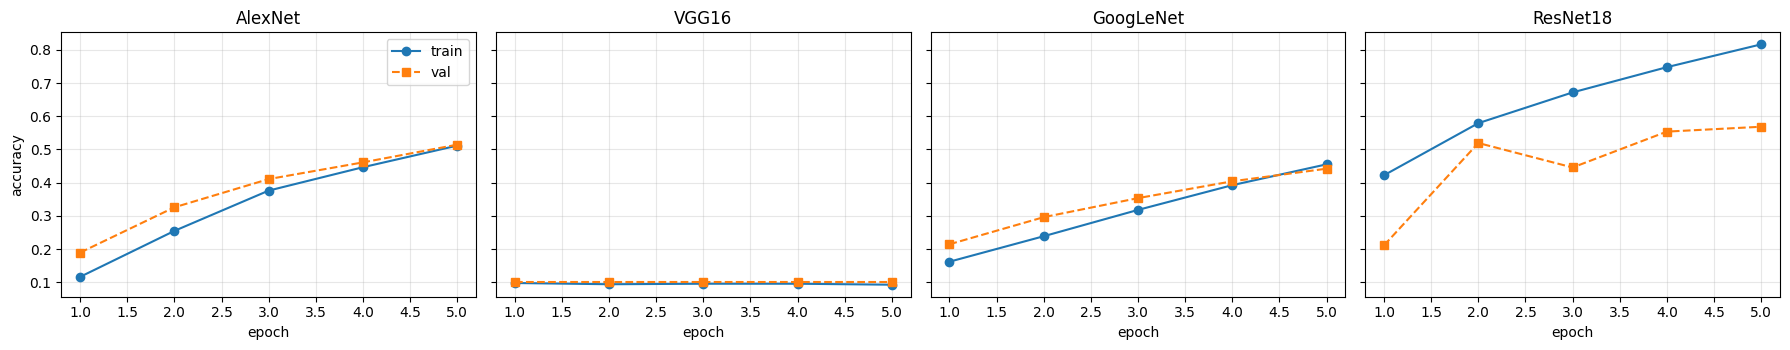

In [ ]:
fig, ax = plt.subplots(1,4, figsize=(18,3.6), sharey=True)
for a,(n,h) in zip(ax, arch_hist.items()):
    if h is None: a.set_title(n+' (failed)'); continue
    e = range(1,len(h['accuracy'])+1)
    a.plot(e,h['accuracy'],'o-',label='train'); a.plot(e,h['val_accuracy'],'s--',label='val')
    a.set_title(n); a.set_xlabel('epoch'); a.grid(alpha=.3)
ax[0].set_ylabel('accuracy'); ax[0].legend(); plt.tight_layout(); plt.savefig('fig_architectures.png', dpi=160); plt.show()

## 5. Controlled ablation A0 → A1 → A2 → A3-P / A3-R (64×64, seeds 42 & 123) and separate A4 transfer branch

In [ ]:
ABL_EPOCHS = 10
abl_hist = {}
for seed in (42, 123):
    for v in ('A0','A1','A2','A3P','A3R'):
        row, h = run_experiment(f'{v}_s{seed}', (lambda v=v, seed=seed: build_ablation(v, seed=seed)),
            ds(x_tr,y_tr,ABL,True), ds(x_val,y_val,ABL,False), y_val,
            arch=v, input_size=ABL, seed=seed, epochs=ABL_EPOCHS, lr=LR,
            note={'A0':'baseline','A1':'+BN','A2':'+augmentation','A3P':'deeper plain (more params than A2)',
                  'A3R':'A3P + shortcuts (adds 1x1 projection params)'}[v])
        abl_hist[(v,seed)] = h; print(v, seed, row.get('best_val_acc'))
print('param check  A3P vs A3R:', build_ablation('A3P').count_params(), build_ablation('A3R').count_params())

Epoch 1/10
375/375 - 11s - 29ms/step - accuracy: 0.1709 - loss: 2.2013 - val_accuracy: 0.1943 - val_loss: 2.1158
Epoch 2/10
375/375 - 2s - 6ms/step - accuracy: 0.2167 - loss: 2.0864 - val_accuracy: 0.2217 - val_loss: 2.0769
Epoch 3/10
375/375 - 2s - 6ms/step - accuracy: 0.2328 - loss: 2.0554 - val_accuracy: 0.2260 - val_loss: 2.0408
Epoch 4/10
375/375 - 3s - 7ms/step - accuracy: 0.2441 - loss: 2.0298 - val_accuracy: 0.2567 - val_loss: 2.0212
Epoch 5/10
375/375 - 3s - 7ms/step - accuracy: 0.2523 - loss: 2.0094 - val_accuracy: 0.2747 - val_loss: 1.9942
Epoch 6/10
375/375 - 3s - 8ms/step - accuracy: 0.2596 - loss: 1.9906 - val_accuracy: 0.2590 - val_loss: 1.9878
Epoch 7/10
375/375 - 3s - 7ms/step - accuracy: 0.2688 - loss: 1.9745 - val_accuracy: 0.2777 - val_loss: 1.9577
Epoch 8/10
375/375 - 2s - 6ms/step - accuracy: 0.2758 - loss: 1.9590 - val_accuracy: 0.2860 - val_loss: 1.9485
Epoch 9/10
375/375 - 2s - 6ms/step - accuracy: 0.2862 - loss: 1.9414 - val_accuracy: 0.2813 - val_loss: 1.9404

In [ ]:
# A4 transfer: separate branch (ResNet50 ImageNet; 128x128; preprocess_input on 0-255 pixels)
TL_EPOCHS = 5
mk_f = lambda: build_transfer((TL,TL,3))[0]
row, hF = run_experiment('A4F_s42', mk_f, ds(x_tr,y_tr,TL,True,'resnet50'), ds(x_val,y_val,TL,False,'resnet50'),
    y_val, arch='A4-F', input_size=TL, seed=42, epochs=TL_EPOCHS, lr=LR,
    note='SEPARATE branch: ImageNet init + external data; frozen trunk, BN in inference mode'); print(row)
def mk_t():
    m, base = build_transfer((TL,TL,3)); m.load_weights('logs/A4F_s42.weights.h5')
    n = unfreeze_top(base); print('unfrozen (non-BN) layers:', n); return m      # run_experiment recompiles at lr below
row, hT = run_experiment('A4T_s42', mk_t, ds(x_tr,y_tr,TL,True,'resnet50'), ds(x_val,y_val,TL,False,'resnet50'),
    y_val, arch='A4-T', input_size=TL, seed=42, epochs=TL_EPOCHS, lr=1e-5,
    note='fine-tune conv5 stage from A4-F checkpoint; recompiled; lr 1e-5; BN frozen'); print(row)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
375/375 - 50s - 134ms/step - accuracy: 0.6823 - loss: 0.9812 - val_accuracy: 0.8287 - val_loss: 0.4931
Epoch 2/5
375/375 - 52s - 138ms/step - accuracy: 0.8334 - loss: 0.4962 - val_accuracy: 0.8530 - val_loss: 0.4320
Epoch 3/5
375/375 - 21s - 56ms/step - accuracy: 0.8589 - loss: 0.4126 - val_accuracy: 0.8620 - val_loss: 0.3981
Epoch 4/5
375/375 - 15s - 39ms/step - accuracy: 0.8746 - loss: 0.3640 - val_accuracy: 0.8633 - val_loss: 0.3898
Epoch 5/5
375/375 - 15s - 39ms/step - accuracy: 0.8872 - loss: 0.3275 - val_accuracy: 0.8637 - val_loss: 0.3877
{'run_id': 'A4F_s42', 'architecture': 'A4-F', 'input_size': 128, 'seed': 42, 'trainable_params': 20490, 'total_params': 23608202, 'epochs': 5, 'batch_size': 32, 'lr': 0.0003, 'best_epoch': 5, 'best_val_acc': 0.8637, 'macro_f1': 0.8628, 'train_acc_at_best': 0.8872, 'final_train_acc': 0.8872, 'gen_gap': 0.0235, 'train_minutes': 2.54, 'peak_gpu_mb': 2248.7, 'status': 'ok', 'failed_batch_

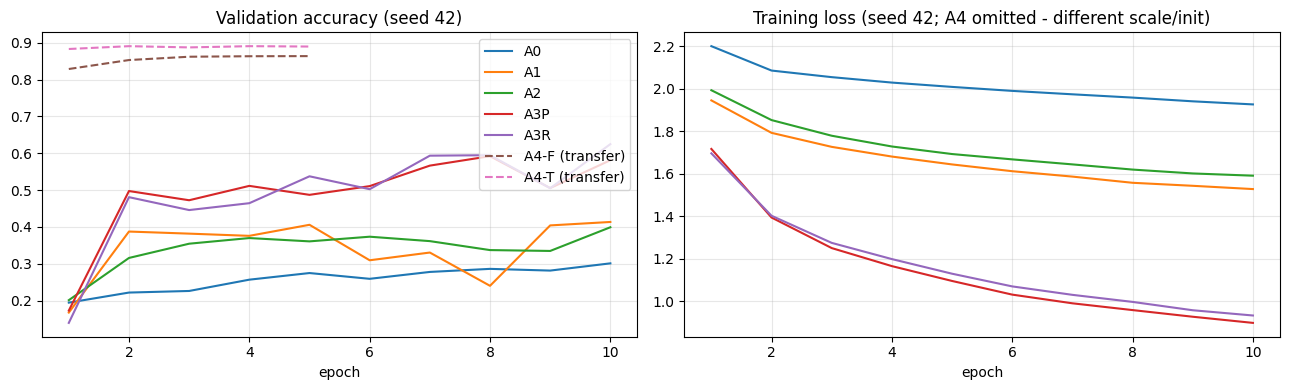

In [ ]:
fig, ax = plt.subplots(1,2, figsize=(13,4))
sty = {'A0':'C0','A1':'C1','A2':'C2','A3P':'C3','A3R':'C4'}
for (v,s),h in abl_hist.items():
    if h is None or s!=42: continue
    ax[0].plot(range(1,len(h['val_accuracy'])+1), h['val_accuracy'], color=sty[v], label=v)
    ax[1].plot(range(1,len(h['loss'])+1), h['loss'], color=sty[v], label=v)
for lab,h,c in (('A4-F',hF,'C5'),('A4-T',hT,'C6')):
    if h: ax[0].plot(range(1,len(h['val_accuracy'])+1), h['val_accuracy'], '--', color=c, label=lab+' (transfer)')
ax[0].set_title('Validation accuracy (seed 42)'); ax[1].set_title('Training loss (seed 42; A4 omitted - different scale/init)')
for a in ax: a.set_xlabel('epoch'); a.grid(alpha=.3)
ax[0].legend(); plt.tight_layout(); plt.savefig('fig_ablation.png', dpi=160); plt.show()

## 6. Results table, pre-registered winner, one-time test evaluation, confusion matrix

In [ ]:
res = pd.read_csv('results.csv')
cols = ['run_id','architecture','input_size','seed','trainable_params','total_params','epochs','best_val_acc',
        'macro_f1','final_train_acc','gen_gap','train_minutes','peak_gpu_mb','status','failed_batch_sizes','note']
res[cols].to_csv('results_table.csv', index=False)
abl = res[res.input_size==ABL].groupby('architecture')[['best_val_acc','macro_f1','gen_gap']].agg(['mean','std']).round(4)
display(res[cols]); display(abl)

,run_id,architecture,input_size,seed,trainable_params,total_params,epochs,best_val_acc,macro_f1,final_train_acc,gen_gap,train_minutes,peak_gpu_mb,status,failed_batch_sizes,note
0,AlexNet_s42,AlexNet,96,42,24767882,24767882,5,0.5143,0.5085,0.5115,-0.0028,0.98,1865.9,ok,NaN,scratch; 5-epoch budget equalises data exposur...
1,VGG16_s42,VGG16,96,42,50415434,50415434,5,0.1000,0.0182,0.0926,-0.0023,4.09,2883.9,ok,NaN,scratch; 5-epoch budget equalises data exposur...
2,GoogLeNet_s42,GoogLeNet,96,42,5983802,5983802,5,0.4420,0.4212,0.4551,0.0131,3.64,2311.7,ok,NaN,scratch; 5-epoch budget equalises data exposur...
3,ResNet18_s42,ResNet18,96,42,11181642,11191242,5,0.5683,0.5687,0.8165,0.2482,1.50,2255.3,ok,NaN,scratch; 5-epoch budget equalises data exposur...
4,A0_s42,A0,64,42,20042,20042,10,0.3010,0.2713,0.2873,-0.0137,0.56,2062.7,ok,NaN,baseline
5,A1_s42,A1,64,42,20138,20330,10,0.4133,0.4049,0.4710,0.0577,0.62,1963.5,ok,NaN,+BN
6,A2_s42,A2,64,42,20138,20330,10,0.3990,0.3807,0.4421,0.0431,1.03,2083.5,ok,NaN,+augmentation
7,A3P_s42,A3P,64,42,298026,298986,10,0.5920,0.5821,0.6893,0.0748,2.24,2315.2,ok,NaN,deeper plain (more params than A2)
8,A3R_s42,A3R,64,42,308650,309994,10,0.6247,0.6181,0.6747,0.0501,2.49,2083.7,ok,NaN,A3P + shortcuts (adds 1x1 projection params)
9,A0_s123,A0,64,123,20042,20042,10,0.3003,0.2582,0.2959,-0.0044,0.47,1944.7,ok,NaN,baseline


best_val_acc         macro_f1         gen_gap        
                     mean     std     mean     std    mean     std
architecture                                                      
A0                 0.3006  0.0005   0.2648  0.0093 -0.0091  0.0066
A1                 0.4176  0.0062   0.4072  0.0033  0.0388  0.0267
A2                 0.4176  0.0264   0.4017  0.0297  0.0188  0.0343
A3P                0.5660  0.0368   0.5591  0.0325  0.0752  0.0006
A3R                0.5850  0.0561   0.5815  0.0518  0.0944  0.0626

Pre-registered winner: ResNet18_s42 {"winner_run_id": "ResNet18_s42", "best_val_acc": 0.5683, "rule": "max best_val_acc among 4 scratch architectures; tie -> fewer params"}
{'run_id': 'ResNet18_s42', 'test_acc': 0.5697, 'test_macro_f1': 0.5700483919788784}


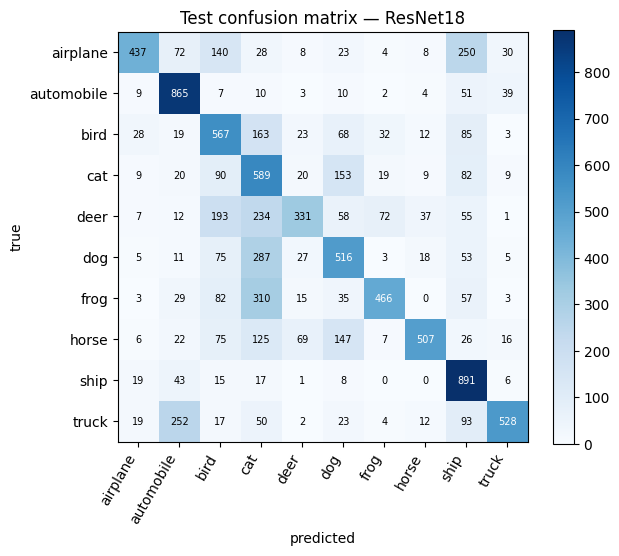

In [ ]:
# Winner is fixed BEFORE touching the test split: best val accuracy among the four scratch architectures.
cands = [f'{n}_s{ARCH_SEED}' for n in MODEL_BUILDERS]
winner = pick_winner(res, cands); print('Pre-registered winner:', winner, open('winner.json').read())
wname = winner.rsplit('_s',1)[0]
test_res, cm = evaluate_on_test_once(MODEL_BUILDERS[wname], winner, xte, yte, BENCH)   # runs exactly once
print(test_res)
fig, a = plt.subplots(figsize=(6.5,5.5)); im = a.imshow(cm, cmap='Blues')
a.set_xticks(range(10)); a.set_yticks(range(10)); a.set_xticklabels(CLASS_NAMES, rotation=60, ha='right'); a.set_yticklabels(CLASS_NAMES)
for i in range(10):
    for j in range(10): a.text(j,i,cm[i,j],ha='center',va='center',fontsize=7,color='white' if cm[i,j]>cm.max()/2 else 'black')
a.set_title(f'Test confusion matrix — {wname}'); a.set_xlabel('predicted'); a.set_ylabel('true')
plt.colorbar(im); plt.tight_layout(); plt.savefig('fig_confusion_matrix.png', dpi=160); plt.show()

### Files to submit
`cnn_assignment.ipynb`, `src/models.py`, `src/utils.py`, `results.csv`, `results_table.csv`, `environment.txt`, `data_indices.npz`, `logs/`, `fig_*.png`, `report.pdf`, `README.md`, `requirements.txt`.

In [20]:
!zip -r logs.zip /content/logs
from google.colab import files
files.download('logs.zip')

updating: content/logs/ (stored 0%)
updating: content/logs/A3R_s42.weights.h5 (deflated 11%)
updating: content/logs/A2_s123.weights.h5 (deflated 22%)
updating: content/logs/A0_s42.weights.h5 (deflated 17%)
updating: content/logs/A3R_s123_history.json (deflated 50%)
updating: content/logs/GoogLeNet_s42.weights.h5 (deflated 11%)
updating: content/logs/VGG16_s42_history.json (deflated 57%)
updating: content/logs/A4T_s42_history.json (deflated 49%)
updating: content/logs/A1_s42_history.json (deflated 51%)
updating: content/logs/A0_s42_history.json (deflated 51%)
updating: content/logs/A3P_s123.weights.h5 (deflated 11%)
updating: content/logs/A3P_s42.weights.h5 (deflated 11%)
updating: content/logs/A1_s123.weights.h5 (deflated 20%)
updating: content/logs/A1_s42.weights.h5 (deflated 20%)
updating: content/logs/A1_s123_history.json (deflated 51%)
updating: content/logs/GoogLeNet_s42_history.json (deflated 46%)
updating: content/logs/A2_s42_history.json (deflated 49%)
updating: content/logs/Al

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>